# ENGS 27 Final Project: Storing Text in DNA

DNA is the densest storage medium known to humans. In principle, one gram of DNA can hold hundreds of
petabytes. Your job is to design a code that stores English text in strands of DNA, over the
four bases **A, C, G, T**, and recovers it after sequencing.

**The channel.** Strands are "synthesized", then sequenced. Each *read* is a random piece (substring) of one of your strands. You will need to study how these strands break up by sending in test strands and gathering statistics. Insights from your tests should help you design your proceedure!

**What you hand in.** A file `solution.py` defining two functions:

- `encode(text)`, which takes a string and returns a list of strands, each a string of
  `A`, `C`, `G` and `T`;
- `decode(reads)`, which takes a list of reads and returns the text.

You will also hand in a **one-page write-up** (one side, 12-point font) describing what you learned about the channel, how your design responds to it, and the evidence for both.

`decode` sees only the reads, so anything it needs, such as how long the text was, has to be stored in the strands that you send in from the encoder. For example, if you use a Huffman tree, you also need to send the tree in your message.

**How it is graded.** Your functions are run on three passages of English text, one short, one
medium and one long, which you will not see in advance. For each passage, your strands go through
the hidden channel, and `decode` receives a fixed total of **4 reads for every character of the
passage**. For example, you will get 4,000 reads for a 1,000-character passage. Each read is a random piece of
a randomly chosen strand, so some strands are read many times and others rarely, or not at all.
Each passage is scored by

$$\text{density} = \frac{8 \times \text{characters}}{\text{bases stored}}, \qquad
e = \frac{\text{edit distance}}{\text{characters}}, \qquad
\text{score} = \text{density} \times \bigl(1 - H(e)\bigr),$$

where $H$ is the binary entropy of Lecture 9, and your grade uses the average over the three passages. Density is bits of text per base, so
compression will be important. The *edit distance* counts the characters you would have to insert, delete or change to fix your output, so dropping one character costs one character (unlike Hamming distance, which would cost a lot in misalignment).

## Setup
Run this cell first. It connects to the course server; no class key is needed.

In [1]:
SERVER_URL = "https://dna.cedar.host.dartmouth.edu"
CLASS_KEY = ""

import random, collections, math
import requests
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs('figures', exist_ok=True)

### Talking to the channel
`Channel().reads(strands, n)` sends your strands to the server and returns `n` reads. There is
no limit on how much you explore. `LocalChannel` does the same on your own computer, for
debugging, but **it is not the real channel**: its breaks happen independently with a fixed
probability. The real channel is more complicated.

In [2]:
class Channel:
    def __init__(self, url=SERVER_URL, key=CLASS_KEY):
        self.url, self.key = url.rstrip("/"), key
        self.max_per_request = requests.get(self.url + "/api/health", timeout=30).json()["limits"]["max_reads_per_request"]

    def reads(self, strands, n):
        got = []
        while len(got) < n:
            ask = min(n - len(got), self.max_per_request)
            r = requests.post(self.url + "/api/reads", timeout=300,
                              json={"key": self.key, "strands": list(strands), "n": ask})
            if r.status_code != 200:
                raise RuntimeError(r.json().get("error", r.text))
            got += r.json()["reads"]
        return got

class LocalChannel:
    def __init__(self, break_prob=0.03, min_read_length=8, seed=None):
        self.p, self.min_len, self.rng = break_prob, min_read_length, random.Random(seed)

    def _one(self, strands):
        while True:
            s = self.rng.choice(strands)
            cuts = [i for i in range(1, len(s)) if self.rng.random() < self.p]
            pieces = [s[a:b] for a, b in zip([0] + cuts, cuts + [len(s)])]
            pieces = [x for x in pieces if len(x) >= self.min_len]
            if pieces:
                return self.rng.choice(pieces)

    def reads(self, strands, n):
        return [self._one(list(strands)) for _ in range(n)]

## Part 1: Explore the channel

Everything below talks to the real server. Each experiment sends strands we know and
compares the reads with them. Results are summarised at the end of Part 1.

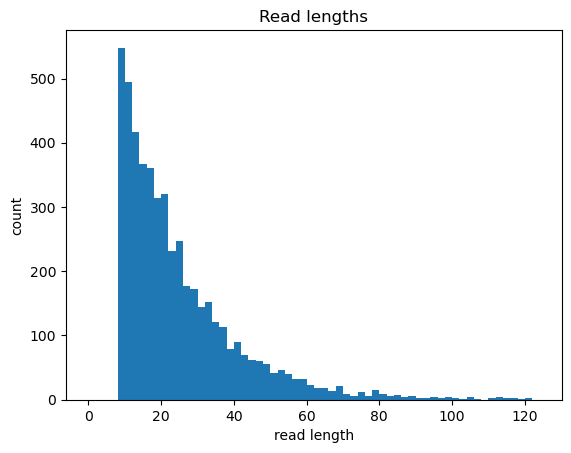

5000 reads, mean length 24.4


In [3]:
channel = Channel()          # or LocalChannel() to practice offline

rng = random.Random(0)
test_strands = ["".join(rng.choice("ACGT") for _ in range(120)) for _ in range(100)]
test_reads = channel.reads(test_strands, 5000)

lengths = [len(r) for r in test_reads]
plt.hist(lengths, bins=range(0, 125, 2))
plt.xlabel("read length"); plt.ylabel("count"); plt.title("Read lengths")
plt.show()
print(f"{len(test_reads)} reads, mean length {np.mean(lengths):.1f}")

Because you know the strands you sent, you can find where each read came from, and so see
exactly where the molecule broke. This helper finds the strand and the starting position of
each read, whenever that is unambiguous.

In [4]:
def locate(reads, strands):
    """For each read, find (strand index, start, length) if it occurs in exactly one strand."""
    out = []
    for r in reads:
        hits = [(j, s.find(r)) for j, s in enumerate(strands) if r in s]
        if len(hits) == 1:
            out.append((hits[0][0], hits[0][1], len(r)))
    return out

located = locate(test_reads, test_strands)
print(f"located {len(located)} of {len(test_reads)} reads")
j, start, n = located[0]
print(f"the first read is strand {j}, bases {start} to {start + n - 1}")

located 4388 of 5000 reads
the first read is strand 88, bases 83 to 105


### 1.1 Are breaks independent? Read lengths vs. a geometric fit

If every site broke independently with one probability $p$, piece lengths would be geometric
(a straight line on a log scale). Reads shorter than 8 bases never come back.

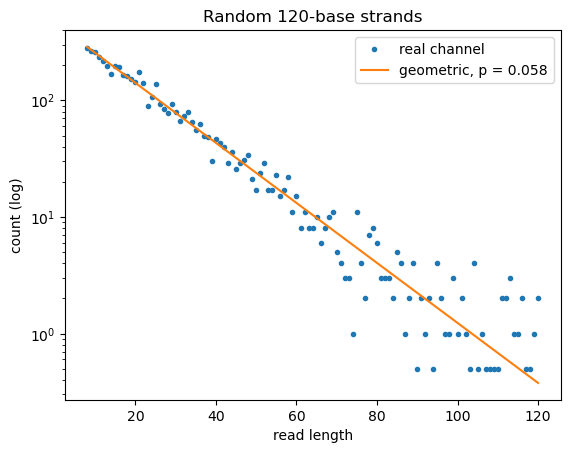

shortest read 8, reads of full length 120: 2


In [5]:
counts = collections.Counter(lengths)
xs = np.arange(8, 121)
ys = np.array([counts.get(x, 0) for x in xs])
p_hat = 1 / (np.mean(lengths) - 7)                       # geometric fit above the 8-base floor
fit = len(lengths) * p_hat * (1 - p_hat) ** (xs - 8)
plt.semilogy(xs, np.maximum(ys, 0.5), ".", label="real channel")
plt.semilogy(xs, fit, "-", label=f"geometric, p = {p_hat:.3f}")
plt.xlabel("read length"); plt.ylabel("count (log)"); plt.legend(); plt.title("Random 120-base strands")
plt.savefig("figures/read_lengths.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"shortest read {min(lengths)}, reads of full length 120: {counts.get(120, 0)}")

### 1.2 Does the chance of a break depend on the bases around it?

For every located read, the end of the read is a cut. Compare how often each local context
appears at a cut with how often it appears in the strands. A ratio of 1 means "no effect".

In [6]:
rng = random.Random(3)
ctx_strands = ["".join(rng.choice("ACGT") for _ in range(200)) for _ in range(100)]
ctx_reads = channel.reads(ctx_strands, 40000)
ctx_loc = locate(ctx_reads, ctx_strands)
print(f"located {len(ctx_loc)} of {len(ctx_reads)} reads")

def cut_ratio(left, right, strands=ctx_strands, loc=ctx_loc, min_occ=30):
    L = len(strands[0])
    cuts, occ = collections.Counter(), collections.Counter()
    for j, p, n in loc:
        e = p + n
        if left <= e <= L - right and e < L:
            cuts[strands[j][e - left:e + right]] += 1
    for s in strands:
        for e in range(left, L - right):
            occ[s[e - left:e + right]] += 1
    tc, to = sum(cuts.values()), sum(occ.values())
    return {k: (cuts[k] / tc) / (occ[k] / to) for k in occ if occ[k] >= min_occ}

for left, right in [(1, 0), (0, 1), (2, 0), (0, 2), (3, 0), (2, 2)]:
    r = cut_ratio(left, right)
    srt = sorted(r.items(), key=lambda kv: -kv[1])
    print(f"{left} left/{right} right: ratio range {min(r.values()):.2f}-{max(r.values()):.2f}  "
          f"top {[(k, round(v, 1)) for k, v in srt[:4]]}")

located 34860 of 40000 reads
1 left/0 right: ratio range 0.18-1.81  top [('C', 1.8), ('G', 1.8), ('A', 0.2), ('T', 0.2)]
0 left/1 right: ratio range 0.96-1.10  top [('C', 1.1), ('G', 1.0), ('A', 1.0), ('T', 1.0)]
2 left/0 right: ratio range 0.15-6.67  top [('CC', 6.7), ('GG', 6.5), ('AC', 0.2), ('AA', 0.2)]
0 left/2 right: ratio range 0.83-1.26  top [('CC', 1.3), ('CT', 1.1), ('TC', 1.1), ('AT', 1.1)]
3 left/0 right: ratio range 0.10-8.20  top [('AGG', 8.2), ('TCC', 7.9), ('ACC', 7.7), ('TGG', 7.3)]
2 left/2 right: ratio range 0.07-7.40  top [('GGCC', 7.4), ('CCCC', 7.4), ('CCCT', 7.3), ('CCGC', 7.3)]


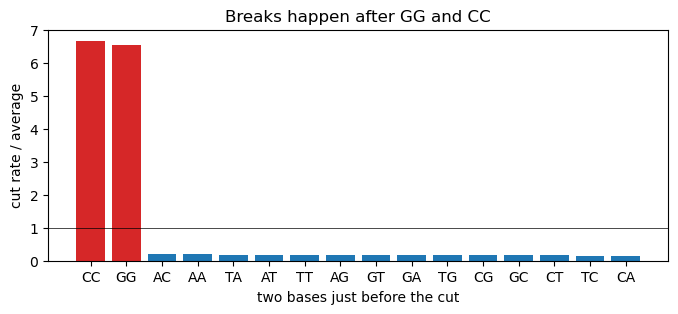

In [7]:
r2 = cut_ratio(2, 0)
keys = sorted(r2, key=lambda k: -r2[k])
plt.figure(figsize=(8, 3))
plt.bar(keys, [r2[k] for k in keys], color=["C3" if k in ("GG", "CC") else "C0" for k in keys])
plt.axhline(1, color="k", lw=0.5)
plt.ylabel("cut rate / average"); plt.xlabel("two bases just before the cut")
plt.title("Breaks happen after GG and CC")
plt.savefig("figures/break_context.png", dpi=150, bbox_inches="tight"); plt.show()

The two bases **left** of the cut decide almost everything: after `GG` or `CC` the cut rate is
about 6x average, everywhere else it is about 0.25x. The bases to the right of the cut do not
matter (ratios stay near 1), and a third base on the left adds nothing beyond the dinucleotide.
So a long random strand is effectively chopped at GG/CC sites, which is why reads average
~25 bases. A strand that never contains `GG` or `CC` should break far less.

### 1.3 How often does a read cover a whole strand of length $L$?

Compare random strands with strands that never contain `GG`/`CC`. If the remaining breaks are
independent with probability $p$ per site, a read is the whole strand with probability
$(1-p)^{L-1}$.

full-length fraction, random     : [0.234, 0.03, 0.0, 0.0, 0.0]
full-length fraction, no GG/CC   : [0.748, 0.556, 0.304, 0.133, 0.048]
fitted p per site with no GG/CC = 0.0100


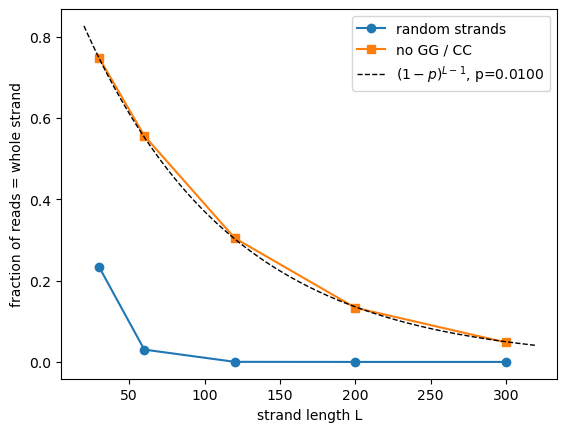

In [8]:
def constrained_strand(L, rng):
    s = [rng.choice("ACGT")]
    while len(s) < L:
        b = rng.choice("ACGT")
        if not (b == s[-1] and b in "GC"):
            s.append(b)
    return "".join(s)

rng = random.Random(5)
Ls = [30, 60, 120, 200, 300]
full_rand, full_ban = [], []
for L in Ls:
    for ban, out in ((False, full_rand), (True, full_ban)):
        S = [constrained_strand(L, rng) if ban else "".join(rng.choice("ACGT") for _ in range(L)) for _ in range(60)]
        R = channel.reads(S, 10000)
        out.append(sum(len(r) == L for r in R) / len(R))
p_fit = np.mean([1 - f ** (1 / (L - 1)) for L, f in zip(Ls, full_ban)])
print("full-length fraction, random     :", [round(f, 3) for f in full_rand])
print("full-length fraction, no GG/CC   :", [round(f, 3) for f in full_ban])
print(f"fitted p per site with no GG/CC = {p_fit:.4f}")
xs = np.arange(20, 320)
plt.plot(Ls, full_rand, "o-", label="random strands")
plt.plot(Ls, full_ban, "s-", label="no GG / CC")
plt.plot(xs, (1 - p_fit) ** (xs - 1), "k--", lw=1, label=f"$(1-p)^{{L-1}}$, p={p_fit:.4f}")
plt.xlabel("strand length L"); plt.ylabel("fraction of reads = whole strand"); plt.legend()
plt.savefig("figures/full_coverage.png", dpi=150, bbox_inches="tight"); plt.show()

### 1.4 Errors inside reads

About one read in ten is not an exact substring of any strand. Align those reads to their
source to see what kind of errors they contain.

In [9]:
def semi_global(r, s):
    """Align all of read r to any part of s. Returns counts of subs / insertions / deletions."""
    n, m = len(r), len(s)
    D = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(1, n + 1):
        D[i][0] = i
        for j in range(1, m + 1):
            D[i][j] = min(D[i-1][j] + 1, D[i][j-1] + 1, D[i-1][j-1] + (r[i-1] != s[j-1]))
    j = min(range(m + 1), key=lambda j: D[n][j]); i = n
    ops = collections.Counter()
    while i > 0:
        if j > 0 and D[i][j] == D[i-1][j-1] + (r[i-1] != s[j-1]):
            ops["sub" if r[i-1] != s[j-1] else "ok"] += 1; i -= 1; j -= 1
        elif D[i][j] == D[i-1][j] + 1:
            ops["ins"] += 1; i -= 1
        else:
            ops["del"] += 1; j -= 1
    return ops

K = 7
seed_index = collections.defaultdict(list)
for j, s in enumerate(ctx_strands):
    for i in range(len(s) - K + 1):
        seed_index[s[i:i+K]].append((j, i))
sample = ctx_reads[:3000]
is_exact = [any(r in s for s in ctx_strands) for r in sample]
bad = [r for r, ok in zip(sample, is_exact) if not ok]
ops = collections.Counter()
for r in bad:
    votes = collections.Counter((j, p - i) for i in range(len(r) - K + 1) for j, p in seed_index.get(r[i:i+K], []))
    if votes:
        (j, off), _ = votes.most_common(1)[0]
        ops += semi_global(r, ctx_strands[j][max(0, off - 4):off + len(r) + 6])
nall = sum(len(r) for r in sample)
print(f"reads with an error: {1 - sum(is_exact) / len(sample):.3f}")
print(f"per base over all reads: substitution {ops['sub'] / nall:.4f}, insertion {ops['ins'] / nall:.4f}, deletion {ops['del'] / nall:.5f}")

by_len = collections.defaultdict(lambda: [0, 0])
for r, ok in zip(sample, is_exact):
    b = min(len(r) // 20, 5); by_len[b][0] += 1; by_len[b][1] += not ok
print("error rate by read length:", {f"{20*b}-{20*b+19}": round(v[1] / v[0], 3) for b, v in sorted(by_len.items())})

reads with an error: 0.112
per base over all reads: substitution 0.0046, insertion 0.0011, deletion 0.00000
error rate by read length: {'0-19': 0.055, '20-39': 0.139, '40-59': 0.204, '60-79': 0.295, '80-99': 0.385, '100-119': 0.455}


### 1.5 Some strands are never read at all

Send 900 strands and ask for 20,000 reads (~22 per strand). Count strands that get no reads,
resend the lost ones to check whether it is the *sequence* that is lost, and repeat at
several lengths.

In [10]:
def reads_per_strand(S, R, k=12):
    idx = collections.defaultdict(set)
    for j, s in enumerate(S):
        for i in range(len(s) - k + 1):
            idx[s[i:i+k]].add(j)
    c = collections.Counter()
    for r in R:
        h = idx.get(r[:k], set()) if len(r) >= k else set()
        if len(h) == 1:
            c[next(iter(h))] += 1
    return [c[j] for j in range(len(S))]

rng = random.Random(11)
S = [constrained_strand(100, rng) for _ in range(900)]
cnt = reads_per_strand(S, channel.reads(S, 20000))
lost = [S[j] for j in range(len(S)) if cnt[j] == 0]
kept = [S[j] for j in range(len(S)) if cnt[j] >= 15][:200]
print(f"strands with zero reads: {len(lost)} of {len(S)} ({len(lost) / len(S):.1%})")
again = reads_per_strand(lost + kept, channel.reads(lost + kept, 10000))
print(f"resent: previously lost still lost {sum(c == 0 for c in again[:len(lost)])}/{len(lost)}, "
      f"previously kept now lost {sum(c == 0 for c in again[len(lost):])}/{len(kept)}")
loss_by_L = {}
for L in (40, 100, 200, 400):
    n = min(800, 90000 // L)
    S = [constrained_strand(L, rng) for _ in range(n)]
    c = reads_per_strand(S, channel.reads(S, 20 * n))
    loss_by_L[L] = sum(x == 0 for x in c) / n
print("loss rate by strand length:", {L: f"{v:.1%}" for L, v in loss_by_L.items()})

strands with zero reads: 30 of 900 (3.3%)


resent: previously lost still lost 29/30, previously kept now lost 0/200


loss rate by strand length: {40: '3.2%', 100: '3.1%', 200: '3.8%', 400: '1.8%'}


### Summary of the channel

| what | measured | consequence for the design |
|---|---|---|
| breaks | after `GG` or `CC`: p ≈ 0.25; elsewhere p ≈ 0.010, independent | never write `GG`/`CC` (costs 8.6%: 1.83 instead of 2 bits/base) |
| full reads | with no GG/CC: $(1-p)^{L-1}$ with p ≈ 0.010 (74% at L=30, 30% at L=120) | strands of 250–450 bases still get dozens of whole-strand reads |
| read errors | ≈0.5% per base: ~85% substitutions, ~15% insertions | vote across many whole-strand reads; CRC on every strand |
| lost strands | ≈3% of strands never come back, fixed per sequence, not tied to length or motif | Reed–Solomon parity strands across strands |
| coverage | 4 reads/char at ~2 bases/char → ~2 reads per stored base, each 50–100 bases long | coverage is plentiful: compression is the main lever |

## Part 2: Our solution

* **Compression.** A small bitwise context-mixing model (orders 0–4 and 6, plus a word
  model, mixed by an online logistic mixer, with an APM stage), driving a binary arithmetic coder.
  It is adaptive: the decoder learns the same model while decoding, so no table is sent.
  An end-of-text flag replaces a length header. About 3.5–4 bits/char on English, against 8 for raw bytes.
* **Constrained code.** Each strand's bits are one big integer, *unranked* into the
  set of length-$L$ strings with no `GG` and no `CC` (enumerative coding, exactly
  $\lfloor\log_2 N(L)\rfloor \approx 1.83L$ bits). One strand error never spreads to another strand.
* **Strand format.** `[index 8 bits | number of data strands 8 bits | payload | CRC-8]`.
* **Erasure code.** Systematic Cauchy Reed–Solomon over GF(256) across strands: any `r` lost
  strands can be rebuilt from `r` parity strands.
* **Choosing L and r.** For each passage the encoder picks the strand length and number of parity
  strands that maximise expected score, $\text{density} \times P(\text{at most } r \text{ strands fail})$,
  where a strand fails if it is lost (3.5%) or gets fewer than 8 whole-strand reads (Poisson model).
* **Decoding.** The strand length shows up as a spike in the read-length histogram. Whole-strand
  reads are clustered by Hamming distance, each cluster gets a per-position majority vote, the
  consensus is ranked back to bits and CRC-checked, missing strands are rebuilt from parity, and
  the stream is decompressed. If too many strands are missing, we decode up to the first gap.

**This cell is the solution.** Running it saves `solution.py`, the file we hand in.

In [11]:
%%writefile solution.py
"""ENGS 27 final project: storing English text in DNA.

Pipeline
  encode: text -> context-mixing compressor -> bit stream
          -> split into strands of equal length L, each strand = [index | payload | CRC-8]
          -> each strand's bits are mapped to a DNA string with NO "GG" and NO "CC"
             (enumerative code; the real channel breaks ~25x more often after GG/CC)
  decode: estimate L from the spike in the read-length histogram (full-length reads)
          -> cluster full-length reads by Hamming distance, per-position majority vote
          -> unrank each consensus, check CRC, keep the best-supported copy of each index
          -> concatenate payloads and decompress; stop at the first missing strand.

Nothing about the text is shared outside the strands: the compressor is adaptive and
the decoder rebuilds the same model as it goes.
"""
import collections
import math

# ----------------------------------------------------------------------------------
# Tunable parameters
# ----------------------------------------------------------------------------------
CRC_BITS = 8
HDR_BITS = 16      # 8-bit strand index + 8-bit number of data strands
P_LOST = 0.035     # measured ~3% of strands never come back; plan for a bit more
P_BREAK = 0.0101   # measured break probability per site once GG/CC are banned
L_RANGE = range(60, 801, 4)
MIN_FULL = 8       # want at least this many full-length reads per strand
MAX_FAIL = 1.0     # cap on P(passage unrecoverable); 1.0 = pure expected-score maximising

# ----------------------------------------------------------------------------------
# 1. Compressor: tiny bitwise context mixing (orders 0-4, 6 and a word model)
# ----------------------------------------------------------------------------------
_PREC = 1 << 16


def _stretch(p):
    return math.log(p / (1 - p))


def _squash(x):
    if x > 30:
        x = 30
    elif x < -30:
        x = -30
    return 1 / (1 + math.exp(-x))


class _BitCoder:
    """Binary arithmetic coder, 32-bit range. Encoder when bits is None."""

    def __init__(self, bits=None):
        self.lo, self.hi = 0, 0xFFFFFFFF
        self.bits = bits
        if bits is None:
            self.out = []
        else:
            self.pos, self.x = 0, 0
            for _ in range(32):
                self.x = (self.x << 1) | self._nb()

    def _nb(self):
        b = self.bits[self.pos] if self.pos < len(self.bits) else 0
        self.pos += 1
        return b

    def code(self, p1, bit=None):
        q = min(max(int(p1 * _PREC), 1), _PREC - 1)
        r = self.hi - self.lo
        mid = self.lo + (r >> 16) * q + (((r & 0xFFFF) * q) >> 16)
        if bit is None:
            bit = 1 if self.x <= mid else 0
        if bit:
            self.hi = mid
        else:
            self.lo = mid + 1
        while (self.lo ^ self.hi) & 0x80000000 == 0:
            if self.bits is None:
                self.out.append(self.hi >> 31)
            else:
                self.x = ((self.x << 1) & 0xFFFFFFFF) | self._nb()
            self.lo = (self.lo << 1) & 0xFFFFFFFF
            self.hi = ((self.hi << 1) & 0xFFFFFFFF) | 1
        return bit

    def finish(self):
        for i in range(32):
            self.out.append((self.lo >> (31 - i)) & 1)
            pref = self.lo >> (31 - i) << (31 - i)
            if pref >= self.lo and (pref | ((1 << (31 - i)) - 1)) <= self.hi:
                break
        return self.out


class _Model:
    ORDERS = (1, 2, 3, 4, 6)
    LR0, LR1, LIMIT = 0.01, 0.3, 255     # mixer learning rate decays as the text goes on

    def __init__(self):
        self.t = {}
        self.w = {}
        self.apm = {}
        self.hist = []
        self.wordh = 0
        self.more = 0      # bytes seen, drives the end-of-text flag

    def p_more(self):
        return (self.more + 1) / (self.more + 2)

    def code_byte(self, coder, byte=None):
        h = self.hist
        cs = [("o0", 0)]
        for k in self.ORDERS:
            cs.append((k, bytes(h[-k:])) if len(h) >= k else (k, None))
        cs.append(("w", self.wordh))
        node = 1
        last = h[-1] if h else 0
        lr = self.LR0 + self.LR1 / math.sqrt(1 + len(h))
        for i in range(8):
            bit_in = None if byte is None else (byte >> (7 - i)) & 1
            slots, st = [], []
            for m, c in cs:
                if c is None:
                    slots.append(None)
                    st.append(0.0)
                    continue
                key = (m, c, node)
                e = self.t.get(key)
                if e is None:
                    e = self.t[key] = [0.5, 0]
                slots.append(e)
                st.append(_stretch(min(max(e[0], 1e-4), 1 - 1e-4)) if e[1] else 0.0)
            st.append(0.3)
            sel = (node, min(len(h), 2))
            w = self.w.get(sel)
            if w is None:
                w = self.w[sel] = [0.3] * len(st)
            dot = sum(a * b for a, b in zip(w, st))
            p = _squash(dot)
            bucket = 0 if dot <= -8 else (32 if dot >= 8 else int((dot + 8) * 2))
            ak = (last, node, bucket)
            a = self.apm.get(ak)
            pf = p if a is None else 0.5 * (p + a)
            bit = coder.code(pf, bit_in)
            a0 = p if a is None else a
            self.apm[ak] = a0 + 0.05 * (bit - a0)
            err = bit - p
            for j in range(len(w)):
                w[j] += lr * err * st[j]
            for e in slots:
                if e is not None:
                    e[1] = min(e[1] + 1, self.LIMIT)
                    e[0] += (bit - e[0]) / (e[1] + 0.5)
            node = node * 2 + bit
        b = node & 0xFF
        h.append(b)
        if 65 <= b <= 90 or 97 <= b <= 122 or b >= 128:
            self.wordh = (self.wordh * 0x2F0B3 + (b | 32) + 1) & 0xFFFFFFFFFF   # explicit, version-proof
        else:
            self.wordh = 0
        return b


def compress(data):
    m, c = _Model(), _BitCoder()
    for b in data:
        c.code(m.p_more(), 1)
        m.more += 1
        m.code_byte(c, b)
    c.code(m.p_more(), 0)
    return c.finish()


def decompress(bits, stop_bit=None, limit=1 << 20):
    """Decode bytes. If stop_bit is given, stop once the decoder has had to read past
    that bit position (the data there is missing, so later output would be garbage)."""
    m, c = _Model(), _BitCoder(bits)
    out = []
    while len(out) < limit:
        if stop_bit is not None and c.pos - 32 > stop_bit:
            break
        if not c.code(m.p_more()):
            break
        m.more += 1
        out.append(m.code_byte(c))
    return bytes(out)


# ----------------------------------------------------------------------------------
# 2. Constrained code: DNA strings with no GG and no CC, ranked as integers
# ----------------------------------------------------------------------------------
BASES = "ACGT"
_COUNT_CACHE = {}


def _ok(prev, b):
    return not (prev == b and b in "GC")


def _counts(n):
    """N[k][prev] = number of valid strings of length k that may follow base prev
    (prev = None at the start)."""
    if n not in _COUNT_CACHE:
        N = [{p: 1 for p in BASES + "S"}]
        for k in range(1, n + 1):
            N.append({p: sum(N[k - 1][b] for b in BASES if p == "S" or _ok(p, b))
                      for p in BASES + "S"})
        _COUNT_CACHE[n] = N
    return _COUNT_CACHE[n]


def capacity(L):
    """Bits one constrained strand of length L can carry."""
    return _counts(L)[L]["S"].bit_length() - 1


def unrank(x, L):
    N, prev, out = _counts(L), "S", []
    for k in range(L, 0, -1):
        for b in BASES:
            if prev != "S" and not _ok(prev, b):
                continue
            c = N[k - 1][b]
            if x < c:
                out.append(b)
                prev = b
                break
            x -= c
    return "".join(out)


def rank(s):
    L = len(s)
    N, prev, x = _counts(L), "S", 0
    for i, ch in enumerate(s):
        if ch not in BASES or (prev != "S" and not _ok(prev, ch)):
            return None
        for b in BASES:
            if b == ch:
                break
            if prev == "S" or _ok(prev, b):
                x += N[L - i - 1][b]
        prev = ch
    return x


# ----------------------------------------------------------------------------------
# 3. Reed-Solomon style erasure code across strands (systematic Cauchy code, GF(256))
# ----------------------------------------------------------------------------------
_EXP, _LOG = [0] * 512, [0] * 256
_v = 1
for _i in range(255):
    _EXP[_i] = _v
    _LOG[_v] = _i
    _v <<= 1
    if _v & 0x100:
        _v ^= 0x11D
for _i in range(255, 512):
    _EXP[_i] = _EXP[_i - 255]


def _gmul(a, b):
    return 0 if a == 0 or b == 0 else _EXP[_LOG[a] + _LOG[b]]


def _ginv(a):
    return _EXP[255 - _LOG[a]]


def _coef(j, i):
    """Coefficient of data strand i in parity strand j: 1 / (x_j + y_i), Cauchy."""
    return _ginv((255 - j) ^ i)


def _parity(data, r):
    K = len(data[0])
    out = []
    for j in range(r):
        p = [0] * K
        for i, d in enumerate(data):
            c = _coef(j, i)
            lc = _LOG[c]
            for t in range(K):
                if d[t]:
                    p[t] ^= _EXP[lc + _LOG[d[t]]]
        out.append(p)
    return out


def _solve_inverse(A):
    """Invert a square matrix over GF(256) (Gauss-Jordan)."""
    m = len(A)
    M = [row[:] + [int(i == j) for j in range(m)] for i, row in enumerate(A)]
    for col in range(m):
        piv = next(r for r in range(col, m) if M[r][col])
        M[col], M[piv] = M[piv], M[col]
        inv = _ginv(M[col][col])
        M[col] = [_gmul(inv, x) for x in M[col]]
        for r in range(m):
            if r != col and M[r][col]:
                f = M[r][col]
                M[r] = [x ^ _gmul(f, y) for x, y in zip(M[r], M[col])]
    return [row[m:] for row in M]


def _recover(data, parity, n):
    """data: {i: bytes-list} for received data strands; parity: {j: list}.
    Returns the full list of n data payloads, or None if not enough survived."""
    missing = [i for i in range(n) if i not in data]
    if not missing:
        return [data[i] for i in range(n)]
    use = sorted(parity)[:len(missing)]
    if len(use) < len(missing):
        return None
    K = len(next(iter(parity.values())))
    rhs = []
    for j in use:
        v = parity[j][:]
        for i, d in data.items():
            c = _coef(j, i)
            for t in range(K):
                if d[t]:
                    v[t] ^= _gmul(c, d[t])
        rhs.append(v)
    Ainv = _solve_inverse([[_coef(j, i) for i in missing] for j in use])
    for a, i in enumerate(missing):
        row = [0] * K
        for b in range(len(use)):
            c = Ainv[a][b]
            if c:
                for t in range(K):
                    if rhs[b][t]:
                        row[t] ^= _gmul(c, rhs[b][t])
        data[i] = row
    return [data[i] for i in range(n)]


# ----------------------------------------------------------------------------------
# 4. Strand framing: [index 8 | n_data 8 | K payload bytes | pad | CRC-8]
# ----------------------------------------------------------------------------------
def _crc(bits, salt=0):
    r = 0x5A ^ salt
    for b in bits:
        r ^= b << 7
        r = ((r << 1) ^ 0x07) & 0xFF if r & 0x80 else (r << 1) & 0xFF
    return [(r >> (CRC_BITS - 1 - i)) & 1 for i in range(CRC_BITS)]


def _to_int(bits):
    x = 0
    for b in bits:
        x = x * 2 + b
    return x


def _to_bits(x, n):
    return [(x >> (n - 1 - i)) & 1 for i in range(n)]


def _K(L):
    """Payload bytes per strand of length L."""
    return (capacity(L) - HDR_BITS - CRC_BITS) // 8


def _frame(index, n, payload, L):
    cap = capacity(L)
    bits = _to_bits(index, 8) + _to_bits(n, 8)
    for byte in payload:
        bits += _to_bits(byte, 8)
    bits += [0] * (cap - CRC_BITS - len(bits))
    bits += _crc(bits, L & 0xFF)
    return unrank(_to_int(bits), L)


def _unframe(strand):
    L = len(strand)
    x = rank(strand)
    if x is None:
        return None
    cap = capacity(L)
    if x >> cap:
        return None
    bits = _to_bits(x, cap)
    if _crc(bits[:-CRC_BITS], L & 0xFF) != bits[-CRC_BITS:]:
        return None
    index, n = _to_int(bits[:8]), _to_int(bits[8:16])
    K = _K(L)
    payload = [_to_int(bits[16 + 8 * t:24 + 8 * t]) for t in range(K)]
    return index, n, payload


# ----------------------------------------------------------------------------------
# 5. Choosing strand length L and number of parity strands r for each passage
# ----------------------------------------------------------------------------------
def _binom_tail_ok(N, r, q):
    """P(at most r of N strands fail), each failing independently with prob q."""
    p, term = 0.0, (1 - q) ** N
    for k in range(r + 1):
        p += term
        term = term * (N - k) / (k + 1) * q / (1 - q) if q < 1 else 0
    return min(p, 1.0)


def _plan(nbits, nchars):
    best = None
    for L in L_RANGE:
        K = _K(L)
        if K < 4:
            continue
        n = max(1, -(-nbits // (8 * K)))
        if n > 200:
            continue
        for r in range(0, min(12, 255 - n) + 1):
            N = n + r
            # reads per surviving strand, and expected full-length reads among them
            lam = 4 * nchars / (N * (1 - P_LOST)) * (1 - P_BREAK) ** (L - 1)
            # P(fewer than MIN_FULL full reads): too few to find L and vote reliably
            term, p_few = math.exp(-lam), 0.0
            for k in range(MIN_FULL):
                p_few += term
                term *= lam / (k + 1)
            q = P_LOST + (1 - P_LOST) * p_few
            ok = _binom_tail_ok(N, r, q)
            if 1 - ok > MAX_FAIL:
                continue
            ev = ok / (N * L)
            if best is None or ev > best[0]:
                best = (ev, L, n, r)
    if best is None:
        return _plan_fallback(nbits)
    return best[1:]


def _plan_fallback(nbits):
    L = L_RANGE[-1]
    return L, max(1, -(-nbits // (8 * _K(L)))), 0


# ----------------------------------------------------------------------------------
# 6. encode / decode
# ----------------------------------------------------------------------------------
def encode(text):
    bits = compress(text.encode("utf-8"))
    L, n, r = _plan(len(bits), max(1, len(text)))
    K = _K(L)
    bits = bits + [0] * (n * K * 8 - len(bits))
    data = [[_to_int(bits[8 * (i * K + t):8 * (i * K + t) + 8]) for t in range(K)] for i in range(n)]
    strands = [_frame(i, n, d, L) for i, d in enumerate(data)]
    strands += [_frame(n + j, n, p, L) for j, p in enumerate(_parity(data, r))]
    return strands


def _estimate_L(reads):
    cnt = collections.Counter(len(r) for r in reads)
    best, score = None, -1
    for l, c in cnt.items():
        if l < 12:
            continue
        s = c - cnt.get(l + 2, 0) - cnt.get(l + 3, 0)    # a spike above its neighbours
        if s > score:
            best, score = l, s
    return best


def _consensus_candidates(reads, L):
    """Cluster reads of length exactly L by Hamming distance; return (consensus, support)."""
    full = collections.Counter(r for r in reads if len(r) == L)
    k = 4                                   # pigeonhole: <=3 errors => one chunk exact
    bounds = [(L * j // k, L * (j + 1) // k) for j in range(k)]
    tol = max(3, L // 10)
    clusters = []                           # [rep, Counter-of-reads, total]
    chunk_idx = collections.defaultdict(list)
    for r, c in full.most_common():
        hit, seen = None, set()
        for j, (a, b) in enumerate(bounds):
            for ci in chunk_idx.get((j, r[a:b]), ()):
                if ci in seen:
                    continue
                seen.add(ci)
                if sum(x != y for x, y in zip(clusters[ci][0], r)) <= tol:
                    hit = ci
                    break
            if hit is not None:
                break
        if hit is None:
            hit = len(clusters)
            clusters.append([r, collections.Counter(), 0])
            for j, (a, b) in enumerate(bounds):
                chunk_idx[(j, r[a:b])].append(hit)
        clusters[hit][1][r] += c
        clusters[hit][2] += c
    out = []
    for rep, members, total in clusters:
        if total > 1:
            cols = [collections.Counter() for _ in range(L)]
            for r, c in members.items():
                for i, ch in enumerate(r):
                    cols[i][ch] += c
            cons = "".join(col.most_common(1)[0][0] for col in cols)
            out.append((cons, total))
            if cons != rep:
                out.append((rep, members[rep]))
        else:
            out.append((rep, 1))
    return out


def decode(reads):
    try:
        return _decode(reads)
    except Exception:
        return ""


def _decode(reads):
    reads = [r for r in reads if r]
    if not reads:
        return ""
    # Try the likely strand lengths; keep the one whose reads decode to the most
    # CRC-valid strands (weighted by how many reads support them).
    choice = None
    for L in _candidate_lengths(reads):
        best, nvotes = {}, collections.Counter()
        for cons, support in _consensus_candidates(reads, L):
            got = _unframe(cons)
            if got is None:
                continue
            i, n, payload = got
            nvotes[n] += support
            if i not in best or support > best[i][0]:
                best[i] = (support, payload)
        total = sum(v[0] for v in best.values())
        if best and (choice is None or total > choice[0]):
            choice = (total, L, best, nvotes)
    if choice is None:
        return ""
    _, L, best, nvotes = choice
    n = nvotes.most_common(1)[0][0]
    data = {i: v[1] for i, v in best.items() if i < n}
    parity = {i - n: v[1] for i, v in best.items() if i >= n}
    full = _recover(dict(data), parity, n)
    K = _K(L)
    stop = None
    if full is None:                        # too many losses: decode up to the first gap
        full = []
        for i in range(n):
            if i not in data:
                stop = 8 * K * i
                break
            full.append(data[i])
    bits = []
    for d in full:
        for byte in d:
            bits += _to_bits(byte, 8)
    out = decompress(bits, stop_bit=stop, limit=max(20000, 100 * len(bits)))
    return out.decode("utf-8", errors="replace")


def _candidate_lengths(reads):
    first = _estimate_L(reads)
    cnt = collections.Counter(len(r) for r in reads if len(r) >= 20)
    out = [first, first - 1, first + 1] + [l for l, _ in cnt.most_common(8)]
    # long lengths that occur several times are strong candidates too (full reads)
    out += [l for l, c in cnt.items() if c >= 3 and l >= 60]
    seen, res = set(), []
    for l in out:
        if l and l >= 20 and l not in seen:
            seen.add(l)
            res.append(l)
    return res

Overwriting solution.py


## Part 3: Test it the way it will be graded

`LocalChannel` breaks every site with p = 0.03 and so is much harsher on long strands than the
real channel. We test on a simulator fitted to the Part 1 measurements, then on the real server,
across passages of different lengths and styles.

In [12]:
import random
import zlib

P_HOT, P_COLD, MIN_LEN = 0.25, 0.0101, 8
P_SUB, P_INS, P_DEL = 0.0043, 0.0008, 0.0001
P_LOST = 0.03


class SimChannel:
    def __init__(self, seed=None, p_hot=P_HOT, p_cold=P_COLD, p_sub=P_SUB, p_ins=P_INS, p_del=P_DEL,
                 p_lost=P_LOST):
        self.rng = random.Random(seed)
        self.salt = (seed or 0) * 7919
        self.p_lost = p_lost
        self.p_hot, self.p_cold = p_hot, p_cold
        self.p_sub, self.p_ins, self.p_del = p_sub, p_ins, p_del

    def _one(self, strands):
        rng = self.rng
        while True:
            s = rng.choice(strands)
            cuts = [i for i in range(1, len(s))
                    if rng.random() < (self.p_hot if i >= 2 and s[i - 2] == s[i - 1] and s[i - 1] in "GC" else self.p_cold)]
            pieces = [s[a:b] for a, b in zip([0] + cuts, cuts + [len(s)])]
            pieces = [x for x in pieces if len(x) >= MIN_LEN]
            if pieces:
                return self._noise(rng.choice(pieces))

    def _noise(self, r):
        rng, out = self.rng, []
        for c in r:
            u = rng.random()
            if u < self.p_del:
                continue
            if u < self.p_del + self.p_sub:
                out.append(rng.choice([b for b in "ACGT" if b != c]))
            else:
                out.append(c)
            if rng.random() < self.p_ins:
                out.append(rng.choice("ACGT"))
        return "".join(out)

    def _lost(self, s):
        return (zlib.crc32(s.encode()) ^ self.salt) % 100000 < self.p_lost * 100000

    def reads(self, strands, n):
        strands = [s for s in strands if not self._lost(s)]
        if not strands:
            return []
        return [self._one(strands) for _ in range(n)]

In [13]:
import importlib, solution
importlib.reload(solution)

SAMPLE = """Every living cell carries its instructions written in a four-letter alphabet, and
it copies them with astonishing reliability. Engineers have begun to borrow the idea: a
library's worth of text, written into DNA and dried, could sit on a shelf for thousands of
years without power. The hard part is not the writing but the reading. A sequencer sees only
short fragments, in no particular order, and it is up to the code to put them back together."""

def edit_distance(a, b):
    if a == b: return 0
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def evaluate(text, channel, reads_per_char=4):
    strands = solution.encode(text)
    bases = sum(map(len, strands))
    decoded = solution.decode(channel.reads(strands, reads_per_char * len(text)))
    density = 8 * len(text.encode()) / bases
    e = min(1.0, edit_distance(decoded[:2 * len(text)], text) / len(text))
    info = 0.0 if e >= 0.5 else (1.0 if e == 0 else 1 + e * math.log2(e) + (1 - e) * math.log2(1 - e))
    print(f"{len(strands)} strands, {bases} bases: density {density:.3f}, "
          f"accuracy {1 - e:.4f}, SCORE {density * info:.4f}")
    return density * info

evaluate(SAMPLE, SimChannel(seed=1))
evaluate(SAMPLE, Channel())

4 strands, 1136 bases: density 3.141, accuracy 1.0000, SCORE 3.1408


4 strands, 1136 bases: density 3.141, accuracy 1.0000, SCORE 3.1408


3.140845070422535

In [14]:
import glob
passages = {os.path.basename(f)[:-4]: open(f, encoding="utf-8").read() for f in sorted(glob.glob("texts/*.txt"))}
results = {}
for name, text in passages.items():
    print(f"{name:18s} {len(text):5d} chars: ", end="")
    results[name] = evaluate(text, Channel())
print(f"\nmean score on the real channel: {np.mean(list(results.values())):.3f}  (baseline: 0.87 on SAMPLE)")

long_legal          4000 chars: 

27 strands, 7560 bases: density 4.233, accuracy 1.0000, SCORE 4.2328
long_narrative      2034 chars: 

12 strands, 4224 bases: density 3.852, accuracy 1.0000, SCORE 3.8523
long_news_mix       3266 chars: 

22 strands, 7128 bases: density 3.666, accuracy 1.0000, SCORE 3.6655
long_technical      1993 chars: 

19 strands, 4484 bases: density 3.556, accuracy 1.0000, SCORE 3.5558
medium_dialogue     1179 chars: 

10 strands, 2720 bases: density 3.468, accuracy 1.0000, SCORE 3.4676
medium_narrative    1200 chars: 

9 strands, 2808 bases: density 3.419, accuracy 1.0000, SCORE 3.4188
medium_technical    1000 chars: 

9 strands, 2376 bases: density 3.367, accuracy 1.0000, SCORE 3.3670
short_dialogue       250 chars: 

2 strands, 680 bases: density 2.941, accuracy 1.0000, SCORE 2.9412
short_news           400 chars: 

3 strands, 1056 bases: density 3.030, accuracy 1.0000, SCORE 3.0303
short_poetry         300 chars: 

2 strands, 736 bases: density 3.261, accuracy 1.0000, SCORE 3.2609

mean score on the real channel: 3.479  (baseline: 0.87 on SAMPLE)


In [15]:
# Stress test: random excerpts mean different strands, so different strands get lost.
rng = random.Random(42)
corpus = "\n\n".join(passages.values())
stress = collections.defaultdict(list)
for k in range(24):
    n = rng.choice([150, 400, 1000, 2500, 4000])
    a = rng.randrange(0, len(corpus) - n)
    print(f"excerpt {k:2d} ({n} chars): ", end="")
    stress[n].append(evaluate(corpus[a:a + n], Channel()))
print({n: round(np.mean(v), 2) for n, v in sorted(stress.items())},
      f"failures: {sum(s == 0 for v in stress.values() for s in v)}/24")

excerpt  0 (150 chars): 

1 strands, 380 bases: density 3.158, accuracy 1.0000, SCORE 3.1579
excerpt  1 (1000 chars): 

9 strands, 2412 bases: density 3.317, accuracy 1.0000, SCORE 3.3167
excerpt  2 (400 chars): 

3 strands, 960 bases: density 3.333, accuracy 1.0000, SCORE 3.3333
excerpt  3 (150 chars): 

2 strands, 448 bases: density 2.679, accuracy 1.0000, SCORE 2.6786
excerpt  4 (4000 chars): 

30 strands, 8520 bases: density 3.756, accuracy 1.0000, SCORE 3.7559
excerpt  5 (4000 chars): 

... (15 outputs left out)

2 strands, 464 bases: density 2.586, accuracy 1.0000, SCORE 2.5862
excerpt 21 (150 chars): 

2 strands, 424 bases: density 2.830, accuracy 1.0000, SCORE 2.8302
excerpt 22 (1000 chars): 

9 strands, 2520 bases: density 3.175, accuracy 1.0000, SCORE 3.1746
excerpt 23 (1000 chars): 

9 strands, 2484 bases: density 3.221, accuracy 1.0000, SCORE 3.2206
{150: 2.33, 400: 3.37, 1000: 3.22, 2500: 3.43, 4000: 4.27} failures: 1/24


## Doing better

There are many directions, and they combine:

- **Compress** (Lectures 9 and 10). English is far from random, so a code built for it, such as
  a Huffman code, stores the same text in fewer bits. Your decoder needs the code too.
- **Choose the strand length** (Lectures 7 and 23). Long strands waste fewer bases on indices,
  but are less likely to survive in one piece.
- **Assemble overlapping reads** (Lecture 15). Fragments that overlap can be stitched together,
  as in a de Bruijn graph, so strands need not be read whole.
- **Avoid repeats** (Problem Set 6). Substrings that repeat or overlap themselves make
  fragments hard to place.
- **Avoid what breaks** (Lecture 18). If some sequences break more often, a constrained code
  that never writes them keeps strands whole; counting the strings it allows tells you how many
  bits per base it can carry.
- **Add redundancy** (Lecture 11). Some strands may never be read well, some may be lost
  entirely, and reads may contain errors. Parity checks or other codes across strands can recover them for far less than
  storing everything twice.
- **Plan the coverage** (Lectures 6 and 7). With 4 reads per character, work out how many
  reads each strand gets, and how likely one is to be missed: a coupon collector problem.

**What to hand in:** `solution.py`, and the one-page write-up.